In [12]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = [12, 4.5]

raw = pd.read_csv("conjura_mmm_data.csv", parse_dates=["DATE_DAY"])

print("Shape (rows, columns):", raw.shape)
print("Number of brands:     ", raw["ORGANISATION_ID"].nunique())
print("Number of time series:", raw["MMM_TIMESERIES_ID"].nunique())
print("Date range:", raw["DATE_DAY"].min().date(), "to", raw["DATE_DAY"].max().date())
print("Exact duplicate rows:", raw.duplicated().sum())
print()
print(raw.dtypes.value_counts())

Shape (rows, columns): (132759, 50)
Number of brands:      93
Number of time series: 143
Date range: 2019-07-21 to 2024-06-02
Exact duplicate rows: 0

float64           37
object             8
int64              4
datetime64[ns]     1
Name: count, dtype: int64


In [13]:
SPEND_COLS = [c for c in raw.columns if c.endswith("_SPEND")]
print("The 9 spend columns:", SPEND_COLS)
print()
print("Share of empty cells in the whole file: %.1f%%" % (raw.isna().values.mean() * 100))
print()
print("Empty cells per spend column (%):")
print(raw[SPEND_COLS].isna().mean().mul(100).round(1).sort_values(ascending=False))

The 9 spend columns: ['GOOGLE_PAID_SEARCH_SPEND', 'GOOGLE_SHOPPING_SPEND', 'GOOGLE_PMAX_SPEND', 'GOOGLE_DISPLAY_SPEND', 'GOOGLE_VIDEO_SPEND', 'META_FACEBOOK_SPEND', 'META_INSTAGRAM_SPEND', 'META_OTHER_SPEND', 'TIKTOK_SPEND']

Share of empty cells in the whole file: 38.2%

Empty cells per spend column (%):
TIKTOK_SPEND                97.4
GOOGLE_VIDEO_SPEND          94.3
GOOGLE_DISPLAY_SPEND        85.9
META_OTHER_SPEND            82.3
META_INSTAGRAM_SPEND        79.8
GOOGLE_PMAX_SPEND           54.0
GOOGLE_SHOPPING_SPEND       40.5
META_FACEBOOK_SPEND         39.7
GOOGLE_PAID_SEARCH_SPEND    27.2
dtype: float64


In [14]:
rows_per_key = raw.groupby(["MMM_TIMESERIES_ID", "DATE_DAY"]).size()
print("Rows per (series, day) -- should all be 1:")
print(rows_per_key.value_counts())
print()
print("Currencies in the file:", raw["CURRENCY_CODE"].unique())

Rows per (series, day) -- should all be 1:
1    132759
Name: count, dtype: int64

Currencies in the file: ['USD' 'GBP' 'EUR' 'AUD' 'JPY' 'HKD' 'CAD' 'CLP' 'ZAR' 'NZD' 'SEK' 'DKK'
 'NOK' 'CHF']


In [15]:
candidates = []
for sid, g in raw.groupby("MMM_TIMESERIES_ID"):
    g = g.set_index("DATE_DAY").sort_index()
    weekly = g[SPEND_COLS].fillna(0).resample("W-SUN").sum()
    candidates.append({
        "series_id": sid,
        "vertical": g["ORGANISATION_VERTICAL"].iloc[0],
        "subvertical": g["ORGANISATION_SUBVERTICAL"].iloc[0],
        "territory": g["TERRITORY_NAME"].iloc[0],
        "currency": g["CURRENCY_CODE"].iloc[0],
        "days": len(g),
        "missing_days": (g.index.max() - g.index.min()).days + 1 - len(g),
        "weeks": len(weekly),
        "weeks_with_google_search": (weekly["GOOGLE_PAID_SEARCH_SPEND"] > 0).mean(),
        "weeks_with_facebook": (weekly["META_FACEBOOK_SPEND"] > 0).mean(),
    })
candidates = pd.DataFrame(candidates)

qualifies = candidates[
    (candidates["weeks"] >= 150)
    & (candidates["missing_days"] == 0)
    & (candidates["weeks_with_google_search"] >= 0.9)
    & (candidates["weeks_with_facebook"] >= 0.9)
].sort_values("weeks", ascending=False)

print(len(qualifies), "series qualify (out of", len(candidates), ")")
qualifies.round(2)

7 series qualify (out of 143 )


,series_id,vertical,subvertical,territory,currency,days,missing_days,weeks,weeks_with_google_search,weeks_with_facebook
114,ce6be55b8e63d8fc2dbc7071ab15db95,Home & Garden,Bed & Bath,All Territories,GBP,1642,0,236,1.00,0.99
101,c6a5d39d2b6ea6a6b36bd230cb6fd7ac,Beauty & Fitness,Face & Body Care,All Territories,USD,1276,0,183,0.97,1.00
98,c03056f30852c0cf2e0ae70140a1c62d,Apparel,Athletic Apparel,All Territories,GBP,1227,0,177,0.98,0.95
129,ea83e2a2bd0987c6e98dac6f33f73878,Food & Drink,Food,All Territories,USD,1180,0,170,1.00,1.00
64,7907b3524c06df30d23829ad78a5a777,Home & Garden,Home & Interior Decor,UK,GBP,1088,0,156,1.00,0.97
70,826fd57057c52458a1f77cae4e3e6c67,Home & Garden,Home & Interior Decor,All Territories,GBP,1091,0,156,1.00,0.97
14,21ae5756595080e735f52426db421505,Apparel,Other,All Territories,USD,1064,0,152,1.00,1.00


In [16]:
SERIES_ID = qualifies.iloc[0]["series_id"]

df = raw[raw["MMM_TIMESERIES_ID"] == SERIES_ID].copy()
df = df.sort_values("DATE_DAY").set_index("DATE_DAY")

print("Selected series:", SERIES_ID)
print(df[["ORGANISATION_VERTICAL", "ORGANISATION_SUBVERTICAL", "TERRITORY_NAME",
          "CURRENCY_CODE", "ORGANISATION_MARKETING_SOURCES"]].iloc[0])
print()
print("Days:", len(df), "| from", df.index.min().date(), "to", df.index.max().date())

Selected series: ce6be55b8e63d8fc2dbc7071ab15db95
ORGANISATION_VERTICAL               Home & Garden
ORGANISATION_SUBVERTICAL               Bed & Bath
TERRITORY_NAME                    All Territories
CURRENCY_CODE                                 GBP
ORGANISATION_MARKETING_SOURCES       Google, Meta
Name: 2019-11-22 00:00:00, dtype: object

Days: 1642 | from 2019-11-22 to 2024-05-20


In [17]:
full_calendar = pd.date_range(df.index.min(), df.index.max(), freq="D")
print("Missing days:  ", len(full_calendar.difference(df.index)))
print("Duplicate days:", df.index.duplicated().sum())

Missing days:   0
Duplicate days: 0


In [18]:
print("Empty spend cells before filling:")
print(df[SPEND_COLS].isna().sum())

df[SPEND_COLS] = df[SPEND_COLS].fillna(0)

print("\nEmpty cells in sales columns:")
print(df[["ALL_PURCHASES", "ALL_PURCHASES_ORIGINAL_PRICE", "ALL_PURCHASES_GROSS_DISCOUNT"]].isna().sum())

df["NET_SALES"] = df["ALL_PURCHASES_ORIGINAL_PRICE"] - df["ALL_PURCHASES_GROSS_DISCOUNT"]

print("\nDays with spend > 0, per channel:")
print((df[SPEND_COLS] > 0).sum())

Empty spend cells before filling:
GOOGLE_PAID_SEARCH_SPEND       0
GOOGLE_SHOPPING_SPEND       1173
GOOGLE_PMAX_SPEND           1006
GOOGLE_DISPLAY_SPEND        1496
GOOGLE_VIDEO_SPEND          1313
META_FACEBOOK_SPEND           88
META_INSTAGRAM_SPEND        1642
META_OTHER_SPEND            1642
TIKTOK_SPEND                1642
dtype: int64

Empty cells in sales columns:
ALL_PURCHASES                   0
ALL_PURCHASES_ORIGINAL_PRICE    0
ALL_PURCHASES_GROSS_DISCOUNT    0
dtype: int64

Days with spend > 0, per channel:
GOOGLE_PAID_SEARCH_SPEND    1642
GOOGLE_SHOPPING_SPEND        448
GOOGLE_PMAX_SPEND            636
GOOGLE_DISPLAY_SPEND          76
GOOGLE_VIDEO_SPEND           329
META_FACEBOOK_SPEND         1554
META_INSTAGRAM_SPEND           0
META_OTHER_SPEND               0
TIKTOK_SPEND                   0
dtype: int64


In [19]:
days_per_week = df["NET_SALES"].resample("W-SUN").count()
print("Days in each week (first 3 / last 3):", days_per_week.head(3).tolist(), "...", days_per_week.tail(3).tolist())

weekly = df[["NET_SALES", "ALL_PURCHASES"] + SPEND_COLS].resample("W-SUN").sum()
weekly = weekly[days_per_week == 7]

print("\nComplete weeks:", len(weekly), "| from", weekly.index.min().date(), "to", weekly.index.max().date())

Days in each week (first 3 / last 3): [3, 7, 7] ... [7, 7, 1]

Complete weeks: 234 | from 2019-12-01 to 2024-05-19


In [20]:
weekly["TOTAL_SPEND"] = weekly[SPEND_COLS].sum(axis=1)
weekly["OTHER_SPEND"] = (weekly["TOTAL_SPEND"] - weekly["GOOGLE_PAID_SEARCH_SPEND"] - weekly["META_FACEBOOK_SPEND"]).clip(lower=0)

data = weekly[["NET_SALES", "ALL_PURCHASES", "TOTAL_SPEND",
               "GOOGLE_PAID_SEARCH_SPEND", "META_FACEBOOK_SPEND", "OTHER_SPEND"]].copy()

print("Share of total spend by channel:")
print((data[["GOOGLE_PAID_SEARCH_SPEND", "META_FACEBOOK_SPEND", "OTHER_SPEND"]].sum()
       / data["TOTAL_SPEND"].sum()).round(3))
data.head()

Share of total spend by channel:
GOOGLE_PAID_SEARCH_SPEND    0.260
META_FACEBOOK_SPEND         0.573
OTHER_SPEND                 0.167
dtype: float64


,NET_SALES,ALL_PURCHASES,TOTAL_SPEND,GOOGLE_PAID_SEARCH_SPEND,META_FACEBOOK_SPEND,OTHER_SPEND
DATE_DAY,,,,,,
2019-12-01,19695.317379,268,1378.026517,684.51,693.516517,0.000000e+00
2019-12-08,9176.966754,128,636.720000,485.58,151.140000,0.000000e+00
2019-12-15,10126.698283,130,672.417657,489.11,183.307657,2.842171e-14
2019-12-22,7701.820000,96,659.040000,343.30,315.740000,0.000000e+00
2019-12-29,4684.909275,55,578.040000,578.04,0.000000,0.000000e+00


In [21]:
print(data.describe().round(1))

def count_outliers(col):
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)).sum()

print()
for col in ["NET_SALES", "TOTAL_SPEND", "GOOGLE_PAID_SEARCH_SPEND", "META_FACEBOOK_SPEND"]:
    print(f"{col}: {count_outliers(col)} outlier weeks (IQR rule)")

print("\nTop 5 sales weeks:")
print(data["NET_SALES"].sort_values(ascending=False).head(5).round(0))

       NET_SALES  ALL_PURCHASES  TOTAL_SPEND  GOOGLE_PAID_SEARCH_SPEND  \
count      234.0          234.0        234.0                     234.0   
mean     55954.2          724.9       8870.8                    2304.5   
std      30982.7          380.2       6048.2                    1658.5   
min       4530.0           55.0        486.6                     236.7   
25%      35429.3          504.0       3203.9                     986.7   
50%      56455.8          707.5       8699.2                    1970.4   
75%      73909.5          914.8      12995.7                    3432.4   
max     189722.6         2625.0      31933.0                   10609.8   

       META_FACEBOOK_SPEND  OTHER_SPEND  
count                234.0        234.0  
mean                5084.2       1482.1  
std                 3708.5       1911.8  
min                    0.0          0.0  
25%                 2013.0          0.0  
50%                 4787.9        273.6  
75%                 7281.7       2921.3

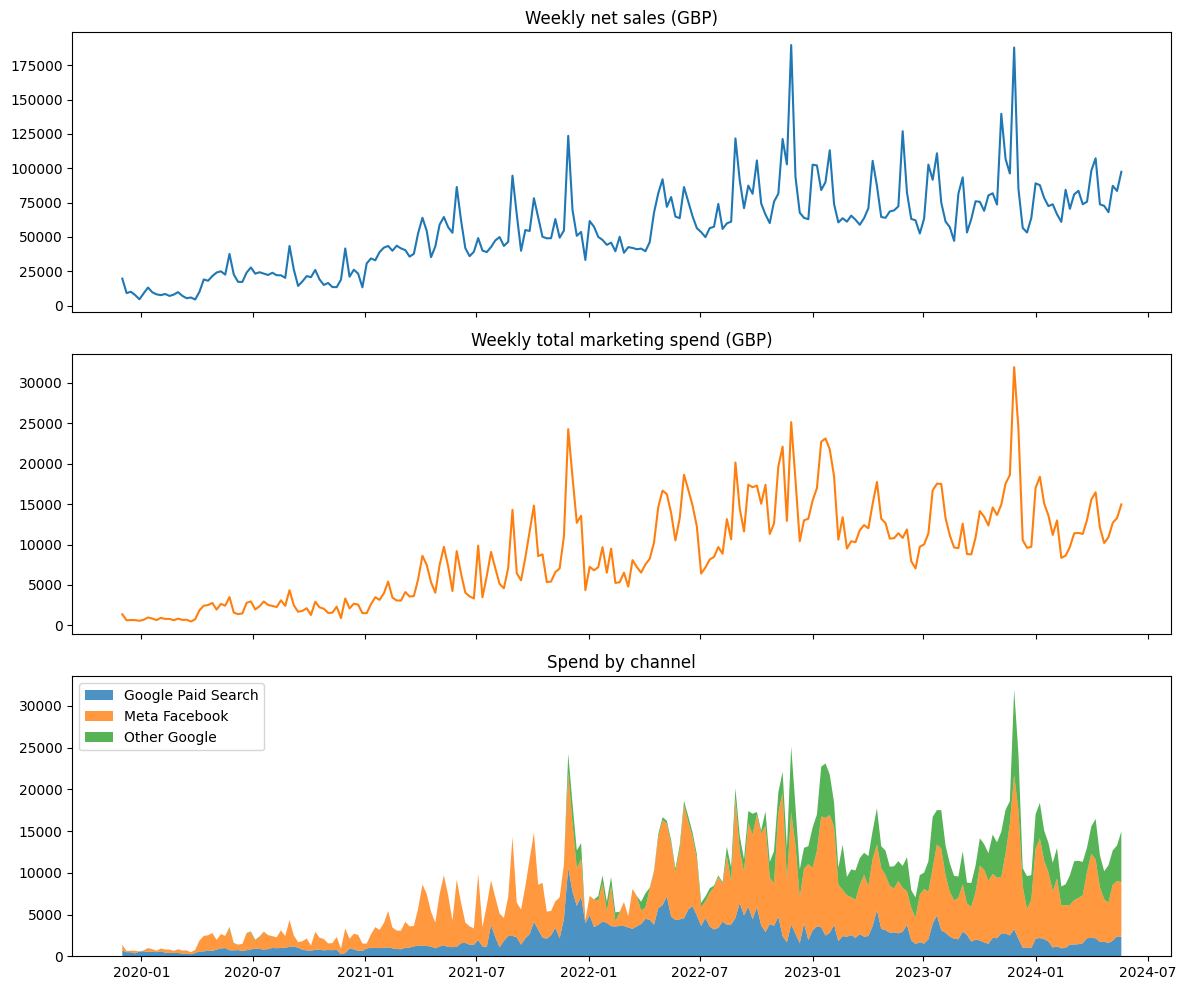

In [22]:
fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
ax[0].plot(data.index, data["NET_SALES"])
ax[0].set_title("Weekly net sales (GBP)")

ax[1].plot(data.index, data["TOTAL_SPEND"], color="tab:orange")
ax[1].set_title("Weekly total marketing spend (GBP)")

ax[2].stackplot(data.index, data["GOOGLE_PAID_SEARCH_SPEND"], data["META_FACEBOOK_SPEND"], data["OTHER_SPEND"],
                labels=["Google Paid Search", "Meta Facebook", "Other Google"], alpha=0.8)
ax[2].set_title("Spend by channel")
ax[2].legend(loc="upper left")
plt.tight_layout()
plt.show()

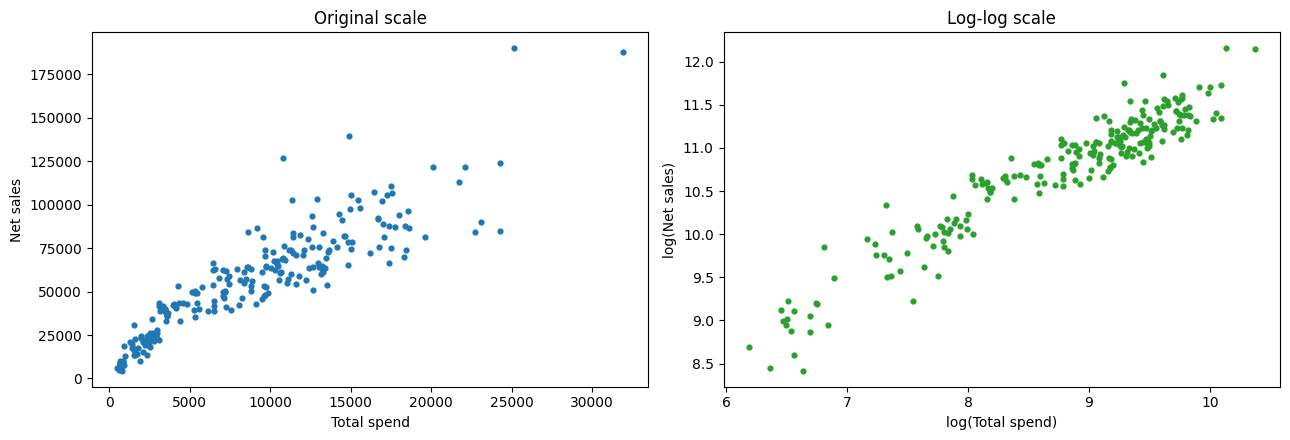

Correlation, original scale: 0.902
Correlation, log-log scale:  0.953


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(data["TOTAL_SPEND"], data["NET_SALES"], s=12)
ax[0].set_xlabel("Total spend"); ax[0].set_ylabel("Net sales"); ax[0].set_title("Original scale")

ax[1].scatter(np.log(data["TOTAL_SPEND"]), np.log(data["NET_SALES"]), s=12, color="tab:green")
ax[1].set_xlabel("log(Total spend)"); ax[1].set_ylabel("log(Net sales)"); ax[1].set_title("Log-log scale")
plt.tight_layout()
plt.show()

print("Correlation, original scale:", round(data["TOTAL_SPEND"].corr(data["NET_SALES"]), 3))
print("Correlation, log-log scale: ", round(np.log(data["TOTAL_SPEND"]).corr(np.log(data["NET_SALES"])), 3))

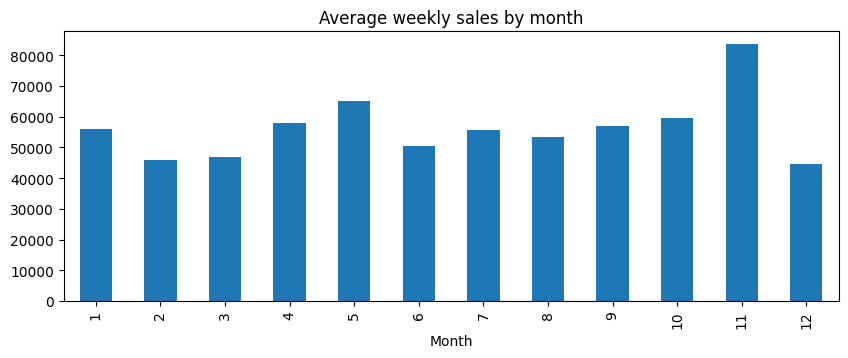

ACF of log sales at lag 52 = 0.224  (95% band = +/-0.128)


In [24]:
from statsmodels.tsa.stattools import acf

monthly_avg = data.groupby(data.index.month)["NET_SALES"].mean()
monthly_avg.plot(kind="bar", title="Average weekly sales by month", figsize=(10, 3.5))
plt.xlabel("Month"); plt.show()

acf_52 = acf(np.log(data["NET_SALES"]), nlags=52)[52]
print(f"ACF of log sales at lag 52 = {acf_52:.3f}  (95% band = +/-{1.96 / np.sqrt(len(data)):.3f})")

In [25]:
print("Weeks with zero TOTAL_SPEND:", (data["TOTAL_SPEND"] == 0).sum())
print("Weeks with zero Google Search spend:", (data["GOOGLE_PAID_SEARCH_SPEND"] == 0).sum())
print("Weeks with zero Facebook spend:", (data["META_FACEBOOK_SPEND"] == 0).sum())

data["log_sales"] = np.log(data["NET_SALES"])
data["log_spend"] = np.log(data["TOTAL_SPEND"])
data["log_google_search"] = np.log1p(data["GOOGLE_PAID_SEARCH_SPEND"])
data["log_facebook"] = np.log1p(data["META_FACEBOOK_SPEND"])
data["log_other"] = np.log1p(data["OTHER_SPEND"])

Weeks with zero TOTAL_SPEND: 0
Weeks with zero Google Search spend: 0
Weeks with zero Facebook spend: 1


In [26]:
def black_friday(year):
    nov1 = pd.Timestamp(year, 11, 1)
    first_thursday = nov1 + pd.Timedelta(days=(3 - nov1.weekday()) % 7)
    return first_thursday + pd.Timedelta(days=22)

def week_contains(week_end, day):
    return week_end - pd.Timedelta(days=6) <= day <= week_end

data["BLACK_FRIDAY"] = [int(week_contains(t, black_friday(t.year))) for t in data.index]
data["CHRISTMAS"] = [int(week_contains(t, pd.Timestamp(t.year, 12, 25))) for t in data.index]

print("Black Friday weeks:", list(data.index[data["BLACK_FRIDAY"] == 1].date))
print("Christmas weeks:   ", list(data.index[data["CHRISTMAS"] == 1].date))

Black Friday weeks: [datetime.date(2019, 12, 1), datetime.date(2020, 11, 29), datetime.date(2021, 11, 28), datetime.date(2022, 11, 27), datetime.date(2023, 11, 26)]
Christmas weeks:    [datetime.date(2019, 12, 29), datetime.date(2020, 12, 27), datetime.date(2021, 12, 26), datetime.date(2022, 12, 25), datetime.date(2023, 12, 31)]


In [27]:
import statsmodels.api as sm

t = np.arange(len(data))
data["sin1"] = np.sin(2 * np.pi * t / 52.18)
data["cos1"] = np.cos(2 * np.pi * t / 52.18)

feature_sets = {
    "spend only": ["log_spend"],
    "spend + holidays": ["log_spend", "BLACK_FRIDAY", "CHRISTMAS"],
    "spend + holidays + Fourier": ["log_spend", "BLACK_FRIDAY", "CHRISTMAS", "sin1", "cos1"],
}
for name, cols in feature_sets.items():
    fit = sm.OLS(data["log_sales"], sm.add_constant(data[cols])).fit()
    print(f"{name:28s} AIC = {fit.aic:8.2f}   R-squared = {fit.rsquared:.3f}")

spend only                   AIC =   -42.05   R-squared = 0.908
spend + holidays             AIC =   -50.35   R-squared = 0.913
spend + holidays + Fourier   AIC =   -48.99   R-squared = 0.914


In [28]:
X_COLS = ["log_spend", "BLACK_FRIDAY", "CHRISTMAS"]
y = data["log_sales"]
X = data[X_COLS]

In [29]:
from statsmodels.tsa.stattools import adfuller, kpss

def stationarity_report(series, name):
    adf_p = adfuller(series.dropna())[1]
    kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
    verdict = "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else "NON-stationary / unclear"
    print(f"{name:26s} ADF p = {adf_p:.4f}   KPSS p = {kpss_p:.3f}   -> {verdict}")

stationarity_report(data["log_sales"], "log_sales")
stationarity_report(data["log_spend"], "log_spend")
stationarity_report(data["log_sales"].diff(), "diff(log_sales)")
stationarity_report(data["log_spend"].diff(), "diff(log_spend)")

log_sales                  ADF p = 0.0633   KPSS p = 0.010   -> NON-stationary / unclear
log_spend                  ADF p = 0.2082   KPSS p = 0.010   -> NON-stationary / unclear
diff(log_sales)            ADF p = 0.0000   KPSS p = 0.100   -> stationary
diff(log_spend)            ADF p = 0.0000   KPSS p = 0.100   -> stationary


C:\Users\Ritarshi Roy\AppData\Local\Temp\ipykernel_6040\1392603905.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
C:\Users\Ritarshi Roy\AppData\Local\Temp\ipykernel_6040\1392603905.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
C:\Users\Ritarshi Roy\AppData\Local\Temp\ipykernel_6040\1392603905.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
C:\Users\Ritarshi Roy\AppData\Local\Temp\ipykernel_6040\1392603905.py:5: Interpola

In [30]:
from statsmodels.tsa.stattools import coint

eg_stat, eg_p, _ = coint(data["log_sales"], data["log_spend"])
print(f"Engle-Granger cointegration test: statistic = {eg_stat:.3f}, p-value = {eg_p:.6f}")

if eg_p < 0.05:
    d = 0
    print("-> p < 0.05: sales and spend are cointegrated, so the regression error is stationary -> keep levels, d = 0")
else:
    d = 1
    print("-> no cointegration: the regression would be spurious in levels -> difference, d = 1")

Engle-Granger cointegration test: statistic = -5.939, p-value = 0.000002
-> p < 0.05: sales and spend are cointegrated, so the regression error is stationary -> keep levels, d = 0


In [31]:
from statsmodels.stats.diagnostic import acorr_ljungbox

print(acorr_ljungbox(data["log_sales"], lags=[4, 8, 12], return_df=True))
print("\np-values ~ 0 -> log sales is NOT white noise: it depends on its own past, so time-series modelling is justified.")

        lb_stat      lb_pvalue
4    680.267147  6.528153e-146
8   1231.532069  1.473746e-260
12  1655.573265   0.000000e+00

p-values ~ 0 -> log sales is NOT white noise: it depends on its own past, so time-series modelling is justified.


In [32]:
N_TEST = 26
y_train, y_test = y.iloc[:-N_TEST], y.iloc[-N_TEST:]
X_train, X_test = X.iloc[:-N_TEST], X.iloc[-N_TEST:]

print(f"Train: {len(y_train)} weeks ({y_train.index.min().date()} to {y_train.index.max().date()})")
print(f"Test:  {len(y_test)} weeks ({y_test.index.min().date()} to {y_test.index.max().date()})")

Train: 208 weeks (2019-12-01 to 2023-11-19)
Test:  26 weeks (2023-11-26 to 2024-05-19)


In [33]:
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:              log_sales   R-squared:                       0.910
Model:                            OLS   Adj. R-squared:                  0.909
Method:                 Least Squares   F-statistic:                     690.1
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.66e-106
Time:                        19:30:22   Log-Likelihood:                 19.668
No. Observations:                 208   AIC:                            -31.34
Df Residuals:                     204   BIC:                            -17.99
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            4.4510      0.140     31.843   

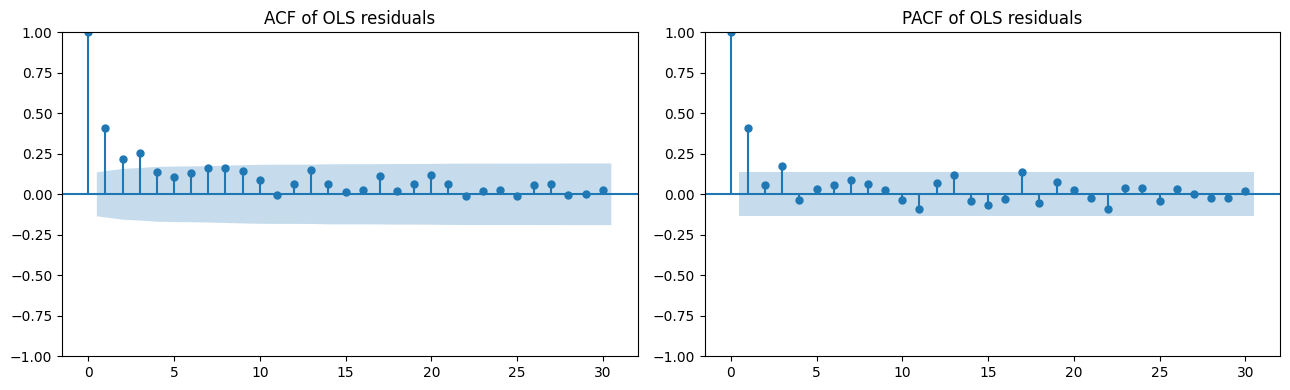

       lb_stat     lb_pvalue
4    62.481011  8.726152e-13
8    80.204328  4.447105e-14
12   87.331647  1.618612e-13
26  102.902101  4.204213e-11

Durbin-Watson = 1.19  (2 = no autocorrelation, < 2 = positive autocorrelation)


In [34]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

ols_resid = ols.resid
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(ols_resid, lags=30, ax=ax[0], title="ACF of OLS residuals")
plot_pacf(ols_resid, lags=30, ax=ax[1], method="ywm", title="PACF of OLS residuals")
plt.tight_layout(); plt.show()

print(acorr_ljungbox(ols_resid, lags=[4, 8, 12, 26], return_df=True))
print(f"\nDurbin-Watson = {sm.stats.durbin_watson(ols_resid):.2f}  (2 = no autocorrelation, < 2 = positive autocorrelation)")

In [35]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

grid = []
for p in range(4):
    for q in range(4):
        fit = SARIMAX(y_train, exog=X_train, order=(p, d, q), trend="c").fit(disp=False, maxiter=500)
        grid.append({"p": p, "q": q, "aic": fit.aic, "bic": fit.bic,
                     "converged": fit.mle_retvals.get("converged", True)})

grid = pd.DataFrame(grid).sort_values("aic").reset_index(drop=True)
print(grid.round(2))

valid = grid[grid["converged"]].reset_index(drop=True)
print(f"\nLowest AIC among converged fits: ARMA({valid.loc[0, 'p']}, {valid.loc[0, 'q']})")
best_bic = valid.sort_values("bic").iloc[0]
print(f"Lowest BIC among converged fits: ARMA({best_bic['p']}, {best_bic['q']})")

    p  q    aic    bic  converged
0   1  2 -86.99 -60.29       True
1   2  2 -86.37 -56.33       True
2   1  3 -86.05 -56.01       True
3   3  2 -84.39 -51.01       True
4   2  3 -84.37 -51.00       True
5   3  1 -83.72 -53.68       True
6   3  3 -82.37 -45.66       True
7   3  0 -81.51 -54.81       True
8   1  1 -77.34 -53.98       True
9   0  3 -69.12 -42.42       True
10  1  0 -69.01 -48.98       True
11  2  0 -68.78 -45.42       True
12  2  1 -65.11 -38.41       True
13  0  1 -61.94 -41.91       True
14  0  2 -61.47 -38.11       True
15  0  0 -29.33 -12.64       True

Lowest AIC among converged fits: ARMA(1, 2)
Lowest BIC among converged fits: ARMA(1, 2)


In [36]:
LB_LAGS = [8, 12, 26, 52]
chosen = None

for _, row in valid.iterrows():
    p, q = int(row["p"]), int(row["q"])
    fit = SARIMAX(y_train, exog=X_train, order=(p, d, q), trend="c").fit(disp=False, maxiter=500)
    lb = acorr_ljungbox(fit.resid, lags=LB_LAGS, model_df=p + q, return_df=True)
    passed = (lb["lb_pvalue"] > 0.05).all()
    print(f"ARMA({p},{q})  AIC = {fit.aic:7.2f}   min Ljung-Box p = {lb['lb_pvalue'].min():.3f}   "
          f"{'PASS -> accept' if passed else 'fail -> back to identification, try next'}")
    if passed:
        chosen = (p, q, fit, lb)
        break

if chosen is None:
    p, q = int(valid.loc[0, "p"]), int(valid.loc[0, "q"])
    fit = SARIMAX(y_train, exog=X_train, order=(p, d, q), trend="c").fit(disp=False, maxiter=500)
    chosen = (p, q, fit, acorr_ljungbox(fit.resid, lags=LB_LAGS, model_df=p + q, return_df=True))
    print("WARNING: no candidate passed Ljung-Box; using the best-AIC model, results need caution")

p, q, model, lb_final = chosen
print(f"\nSelected model: regression with ARMA({p},{q}) errors, d = {d}")

ARMA(1,2)  AIC =  -86.99   min Ljung-Box p = 0.115   PASS -> accept

Selected model: regression with ARMA(1,2) errors, d = 0


In [37]:
print("MLE converged:", model.mle_retvals.get("converged"))
print(model.summary())

print("\n|AR roots|:", np.round(np.abs(model.arroots), 3), "-> stationary" if np.all(np.abs(model.arroots) > 1) else "-> NOT stationary")
print("|MA roots|:", np.round(np.abs(model.maroots), 3), "-> invertible" if np.all(np.abs(model.maroots) > 1) else "-> NOT invertible")

MLE converged: True
                               SARIMAX Results                                
Dep. Variable:              log_sales   No. Observations:                  208
Model:               SARIMAX(1, 0, 2)   Log Likelihood                  51.495
Date:                Tue, 20 Oct 2026   AIC                            -86.990
Time:                        19:30:37   BIC                            -60.290
Sample:                    12-01-2019   HQIC                           -76.194
                         - 11-19-2023                                         
Covariance Type:                  opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
intercept        0.0954      0.087      1.097      0.273      -0.075       0.266
log_spend        0.4790      0.035     13.537      0.000       0.410       0.548
BLACK_FRIDAY     0.3993 

Ljung-Box on final residuals:
      lb_stat  lb_pvalue
8    3.150139   0.676851
12   9.571555   0.386269
26  31.316145   0.115222
52  54.329524   0.278663

Jarque-Bera p-value = 0.008 -> residuals are NOT normal (intervals approximate)


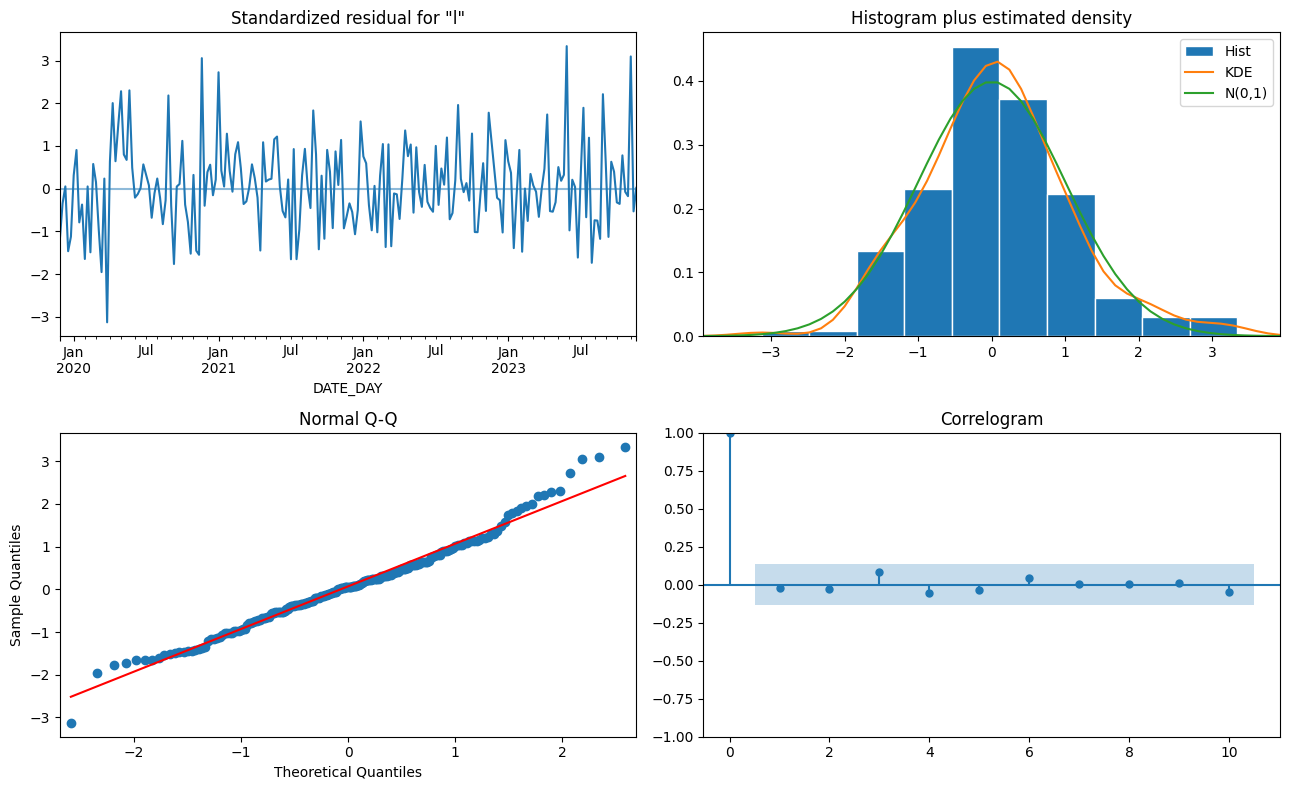

In [38]:
from scipy import stats

print("Ljung-Box on final residuals:")
print(lb_final)
jb_p = stats.jarque_bera(model.resid).pvalue
print(f"\nJarque-Bera p-value = {jb_p:.3f} -> residuals {'look normal' if jb_p > 0.05 else 'are NOT normal (intervals approximate)'}")

model.plot_diagnostics(figsize=(13, 8))
plt.tight_layout(); plt.show()

In [39]:
comparison = pd.DataFrame({
    "OLS": [ols.params["log_spend"], ols.bse["log_spend"], ols.pvalues["log_spend"]],
    f"ARMA({p},{q}) errors": [model.params["log_spend"], model.bse["log_spend"], model.pvalues["log_spend"]],
}, index=["spend elasticity", "standard error", "p-value"])
print(comparison.round(4))
print(f"\nOLS understates the standard error by a factor of {model.bse['log_spend'] / ols.bse['log_spend']:.1f}")

                     OLS  ARMA(1,2) errors
spend elasticity  0.7167            0.4790
standard error    0.0160            0.0354
p-value           0.0000            0.0000

OLS understates the standard error by a factor of 2.2


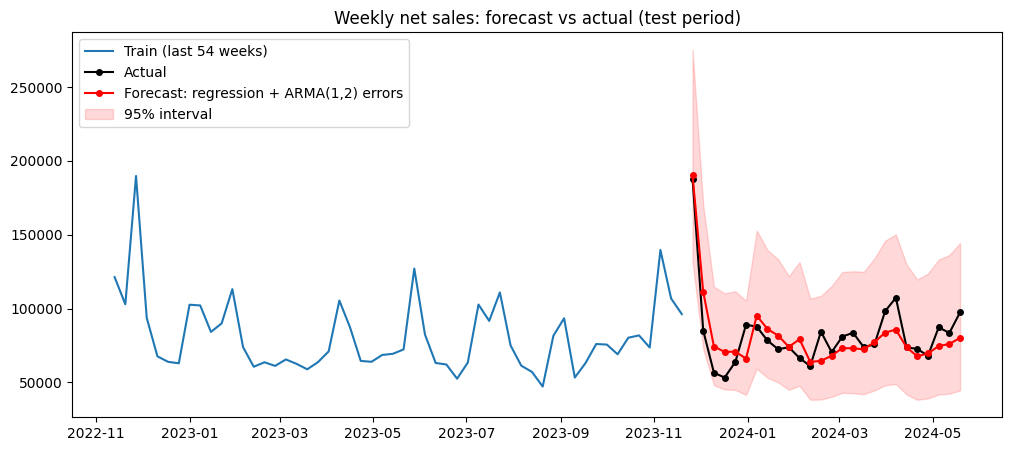

In [40]:
fc = model.get_forecast(steps=N_TEST, exog=X_test)
fc_mean = np.exp(fc.predicted_mean)
fc_ci = np.exp(fc.conf_int(alpha=0.05))
fc_mean.index = y_test.index
fc_ci.index = y_test.index

actual = data["NET_SALES"].iloc[-N_TEST:]

plt.figure(figsize=(12, 5))
plt.plot(data["NET_SALES"].iloc[-80:-N_TEST], label="Train (last 54 weeks)")
plt.plot(actual, "ko-", ms=4, label="Actual")
plt.plot(fc_mean, "ro-", ms=4, label=f"Forecast: regression + ARMA({p},{q}) errors")
plt.fill_between(fc_ci.index, fc_ci.iloc[:, 0], fc_ci.iloc[:, 1], color="red", alpha=0.15, label="95% interval")
plt.title("Weekly net sales: forecast vs actual (test period)")
plt.legend(); plt.show()

In [41]:
sales = data["NET_SALES"]
baselines = {
    f"Regression + ARMA({p},{q}) errors": fc_mean,
    "Naive (last value)": pd.Series(sales.iloc[-N_TEST - 1], index=actual.index),
    "Seasonal naive (last year)": sales.shift(52).iloc[-N_TEST:],
    "Train mean": pd.Series(sales.iloc[:-N_TEST].mean(), index=actual.index),
}

def rmse(a, f): return float(np.sqrt(np.mean((a - f) ** 2)))
def mae(a, f):  return float(np.mean(np.abs(a - f)))
def mape(a, f): return float(np.mean(np.abs((a - f) / a)) * 100)

scores = pd.DataFrame({name: {"RMSE": rmse(actual, f), "MAE": mae(actual, f), "MAPE %": mape(actual, f)}
                       for name, f in baselines.items()}).T
scores.round(2)

,RMSE,MAE,MAPE %
"Regression + ARMA(1,2) errors",12467.99,9902.72,12.55
Naive (last value),28409.42,22359.37,29.04
Seasonal naive (last year),15692.67,12986.03,16.44
Train mean,38297.85,29352.97,31.99


In [42]:
grid_d1 = []
for pp in range(4):
    for qq in range(4):
        fit = SARIMAX(y_train, exog=X_train, order=(pp, 1, qq)).fit(disp=False, maxiter=500)
        grid_d1.append({"p": pp, "q": qq, "aic": fit.aic, "bic": fit.bic,
                        "converged": fit.mle_retvals.get("converged", True)})
grid_d1 = pd.DataFrame(grid_d1).sort_values("aic").reset_index(drop=True)
print(grid_d1.head(8).round(2))

valid_d1 = grid_d1[grid_d1["converged"]].reset_index(drop=True)
for _, row in valid_d1.iterrows():
    p1, q1 = int(row["p"]), int(row["q"])
    d1_model = SARIMAX(y_train, exog=X_train, order=(p1, 1, q1)).fit(disp=False, maxiter=500)
    d1_lb = acorr_ljungbox(d1_model.resid.iloc[1:], lags=LB_LAGS, model_df=p1 + q1, return_df=True)
    passed = (d1_lb["lb_pvalue"] > 0.05).all()
    print(f"ARIMA({p1},1,{q1})  AIC = {d1_model.aic:7.2f}   min Ljung-Box p = {d1_lb['lb_pvalue'].min():.3f}   "
          f"{'PASS -> accept' if passed else 'fail -> try next'}")
    if passed:
        break
print(f"\nComparison model: regression with ARIMA({p1},1,{q1}) errors")

   p  q    aic    bic  converged
0  0  2 -90.66 -70.66       True
1  1  2 -89.59 -66.26       True
2  0  3 -89.29 -65.96       True
3  3  1 -87.97 -61.31       True
4  2  2 -87.78 -61.12       True
5  1  3 -87.67 -61.01       True
6  1  1 -87.35 -67.35       True
7  3  2 -87.01 -57.02       True
ARIMA(0,1,2)  AIC =  -90.66   min Ljung-Box p = 0.220   PASS -> accept

Comparison model: regression with ARIMA(0,1,2) errors


In [43]:
print("MLE converged:", d1_model.mle_retvals.get("converged"))
print(d1_model.summary().tables[1])

ma_roots = np.abs(d1_model.maroots)
print("\n|MA roots|:", np.round(ma_roots, 3))
print("-> no sign of over-differencing (all roots well above 1)" if np.all(ma_roots > 1.1)
      else "-> WARNING: an MA root is close to 1, which suggests over-differencing")

d1_jb = stats.jarque_bera(d1_model.resid.iloc[1:]).pvalue
print("\nLjung-Box on d=1 residuals:")
print(d1_lb)
print(f"Jarque-Bera p-value = {d1_jb:.3f}")

MLE converged: True
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
log_spend        0.4636      0.035     13.237      0.000       0.395       0.532
BLACK_FRIDAY     0.4121      0.198      2.085      0.037       0.025       0.799
CHRISTMAS       -0.3356      0.072     -4.657      0.000      -0.477      -0.194
ma.L1           -0.4168      0.077     -5.384      0.000      -0.568      -0.265
ma.L2           -0.3125      0.070     -4.458      0.000      -0.450      -0.175
sigma2           0.0355      0.003     12.091      0.000       0.030       0.041

|MA roots|: [1.242 2.576]
-> no sign of over-differencing (all roots well above 1)

Ljung-Box on d=1 residuals:
      lb_stat  lb_pvalue
8    2.934876   0.816975
12  10.881829   0.366799
26  28.996076   0.220279
52  56.709097   0.239141
Jarque-Bera p-value = 0.005


In [44]:
d1_fc = d1_model.get_forecast(steps=N_TEST, exog=X_test)
d1_fc_mean = np.exp(d1_fc.predicted_mean)
d1_fc_mean.index = actual.index

def summary_row(m, resid, fc_series, label):
    ci = m.conf_int().loc["log_spend"]
    lbp = acorr_ljungbox(resid, lags=LB_LAGS, model_df=len(m.arparams) + len(m.maparams), return_df=True)["lb_pvalue"].min()
    return pd.Series({
        "spend elasticity": m.params["log_spend"],
        "std error": m.bse["log_spend"],
        "95% CI low": ci.iloc[0], "95% CI high": ci.iloc[1],
        "10% more spend -> % more sales": 100 * (1.10 ** m.params["log_spend"] - 1),
        "min Ljung-Box p": lbp,
        "Jarque-Bera p": stats.jarque_bera(resid).pvalue,
        "test RMSE": rmse(actual, fc_series),
        "test MAPE %": mape(actual, fc_series),
    }, name=label)

compare = pd.concat([
    summary_row(model, model.resid, fc_mean, f"MAIN: d=0, ARMA({p},{q}) errors"),
    summary_row(d1_model, d1_model.resid.iloc[1:], d1_fc_mean, f"COMPARISON: d=1, ARIMA({p1},1,{q1}) errors"),
], axis=1)
compare.round(3)

,"MAIN: d=0, ARMA(1,2) errors","COMPARISON: d=1, ARIMA(0,1,2) errors"
spend elasticity,0.479,0.464
std error,0.035,0.035
95% CI low,0.410,0.395
95% CI high,0.548,0.532
10% more spend -> % more sales,4.671,4.518
min Ljung-Box p,0.115,0.220
Jarque-Bera p,0.008,0.005
test RMSE,12467.993,12167.772
test MAPE %,12.552,13.593


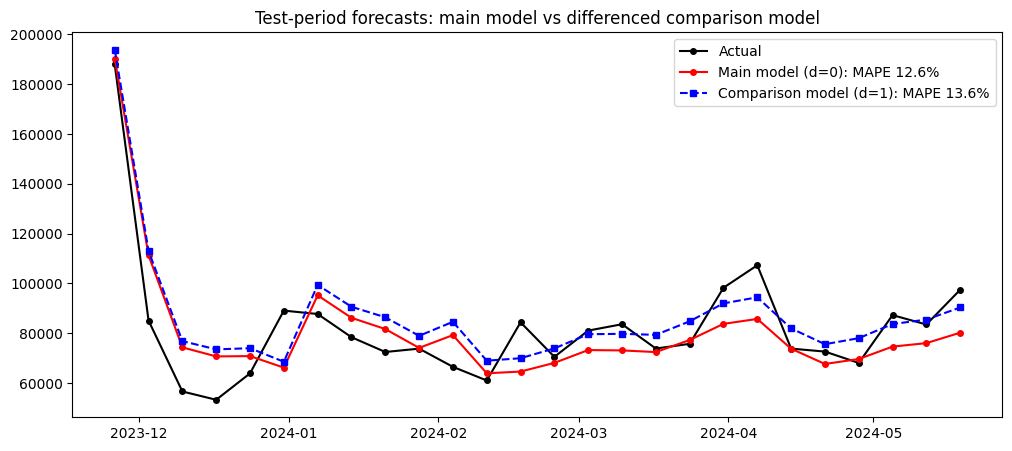

In [45]:
plt.figure(figsize=(12, 5))
plt.plot(actual, "ko-", ms=4, label="Actual")
plt.plot(fc_mean, "ro-", ms=4, label=f"Main model (d=0): MAPE {mape(actual, fc_mean):.1f}%")
plt.plot(d1_fc_mean, "bs--", ms=4, label=f"Comparison model (d=1): MAPE {mape(actual, d1_fc_mean):.1f}%")
plt.title("Test-period forecasts: main model vs differenced comparison model")
plt.legend(); plt.show()

In [46]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

CH_COLS = ["log_google_search", "log_facebook", "log_other", "BLACK_FRIDAY", "CHRISTMAS"]
Xc = data[CH_COLS]
Xc_train, Xc_test = Xc.iloc[:-N_TEST], Xc.iloc[-N_TEST:]

Xv = sm.add_constant(Xc_train)
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=CH_COLS)
print("VIF (above ~5-10 = problematic collinearity):")
print(vif.round(2))
print("\nCorrelations between channel spends (log):")
print(data[["log_google_search", "log_facebook", "log_other"]].corr().round(2))

VIF (above ~5-10 = problematic collinearity):
log_google_search    2.51
log_facebook         2.28
log_other            1.83
BLACK_FRIDAY         1.00
CHRISTMAS            1.16
dtype: float64

Correlations between channel spends (log):
                   log_google_search  log_facebook  log_other
log_google_search               1.00          0.66       0.59
log_facebook                    0.66          1.00       0.59
log_other                       0.59          0.59       1.00


In [47]:
ch_grid = []
for pp in range(4):
    for qq in range(4):
        fit = SARIMAX(y_train, exog=Xc_train, order=(pp, d, qq), trend="c").fit(disp=False, maxiter=500)
        if fit.mle_retvals.get("converged", True):
            ch_grid.append((fit.aic, pp, qq))
ch_grid.sort()

for aic, pp, qq in ch_grid:
    ch_model = SARIMAX(y_train, exog=Xc_train, order=(pp, d, qq), trend="c").fit(disp=False, maxiter=500)
    ch_lb = acorr_ljungbox(ch_model.resid, lags=LB_LAGS, model_df=pp + qq, return_df=True)
    if (ch_lb["lb_pvalue"] > 0.05).all():
        break

print(f"Channel model: ARMA({pp},{qq}) errors, AIC = {ch_model.aic:.2f}, "
      f"min Ljung-Box p = {ch_lb['lb_pvalue'].min():.3f}, converged = {ch_model.mle_retvals.get('converged')}")
print()
ch_table = pd.DataFrame({"elasticity": ch_model.params[["log_google_search", "log_facebook", "log_other"]],
                         "std_err": ch_model.bse[["log_google_search", "log_facebook", "log_other"]],
                         "p_value": ch_model.pvalues[["log_google_search", "log_facebook", "log_other"]]})
ch_table.round(4)

Channel model: ARMA(1,2) errors, AIC = -51.61, min Ljung-Box p = 0.078, converged = True



,elasticity,std_err,p_value
log_google_search,0.1973,0.0419,0.000
log_facebook,0.1727,0.0177,0.000
log_other,0.0160,0.0136,0.242


In [48]:
ch_fc = np.exp(ch_model.get_forecast(steps=N_TEST, exog=Xc_test).predicted_mean)
ch_fc.index = actual.index
print(f"Channel model test MAPE = {mape(actual, ch_fc):.2f}%  "
      f"(total-spend model: {mape(actual, fc_mean):.2f}%)")

Channel model test MAPE = 11.65%  (total-spend model: 12.55%)


In [49]:
avg_sales = data["NET_SALES"].mean()
for col, spend_col in [("log_google_search", "GOOGLE_PAID_SEARCH_SPEND"), ("log_facebook", "META_FACEBOOK_SPEND")]:
    b = ch_model.params[col]
    avg_spend = data[spend_col].mean()
    print(f"{spend_col:26s} elasticity {b:.3f} | avg weekly spend GBP {avg_spend:8.0f} | "
          f"approx. extra sales per extra GBP 1 = GBP {b * avg_sales / avg_spend:.2f}")
print("\n(Approximate, evaluated at average levels; it shows the relative efficiency of the channels, not an exact ROI.)")

GOOGLE_PAID_SEARCH_SPEND   elasticity 0.197 | avg weekly spend GBP     2304 | approx. extra sales per extra GBP 1 = GBP 4.79
META_FACEBOOK_SPEND        elasticity 0.173 | avg weekly spend GBP     5084 | approx. extra sales per extra GBP 1 = GBP 1.90

(Approximate, evaluated at average levels; it shows the relative efficiency of the channels, not an exact ROI.)


In [50]:
final = SARIMAX(y, exog=X, order=(p, d, q), trend="c").fit(disp=False, maxiter=500)
final_lb = acorr_ljungbox(final.resid, lags=LB_LAGS, model_df=p + q, return_df=True)

print("Converged:", final.mle_retvals.get("converged"))
print("Min Ljung-Box p on full-sample residuals:", round(final_lb["lb_pvalue"].min(), 3))
print()

beta = final.params["log_spend"]
ci_low, ci_high = final.conf_int().loc["log_spend"]
print(f"Spend elasticity = {beta:.3f}   (95% CI {ci_low:.3f} to {ci_high:.3f}, p = {final.pvalues['log_spend']:.4g})")
print(f"-> a 10% increase in weekly marketing spend is associated with a {100 * (1.10 ** beta - 1):.1f}% increase in weekly sales")
print(f"   (95% CI {100 * (1.10 ** ci_low - 1):.1f}% to {100 * (1.10 ** ci_high - 1):.1f}%)")

bf = final.params["BLACK_FRIDAY"]; xm = final.params["CHRISTMAS"]
print(f"\nBlack Friday week effect: {100 * (np.exp(bf) - 1):+.1f}% sales (p = {final.pvalues['BLACK_FRIDAY']:.3g})")
print(f"Christmas week effect:    {100 * (np.exp(xm) - 1):+.1f}% sales (p = {final.pvalues['CHRISTMAS']:.3g})")

Converged: True
Min Ljung-Box p on full-sample residuals: 0.103

Spend elasticity = 0.496   (95% CI 0.429 to 0.562, p = 1.517e-48)
-> a 10% increase in weekly marketing spend is associated with a 4.8% increase in weekly sales
   (95% CI 4.2% to 5.5%)

Black Friday week effect: +50.6% sales (p = 0.000812)
Christmas week effect:    -22.5% sales (p = 7.35e-06)
